# Phase 1 — Frozen DINOv2 and the DINOv2 world model (L=14)

**Questions.** (1) How linearly decodable is the snake's head from frozen DINOv2 features (the *ceiling*)? (2) Does a world model trained on those features learn the action-conditioned dynamics, and how do we tell?

**Setup.** 32 episodes × ≤300 steps from the random-backbone Hamiltonian policy (ε = 0.1) on a 14×14 grid, rendered at 224 px. Train/val split by episode (26/6). All numbers below are on the 6 held-out episodes.

Re-run everything with:
```
snek collect --config configs/collect.toml
snek probe --config configs/probe_dinov2.toml
snek wm --config configs/dinov2_wm.toml
snek wm --config configs/dinov2_wm_residual.toml
```

In [1]:
import json
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from snekwm.data.collect import load_episode
from snekwm.env.simulator import ACTIONS
from snekwm.eval import style
from snekwm.eval.probe import fit_probe
from snekwm.experiments.common import load_split

style.apply()
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RESULTS, FIGS = ROOT / "results", ROOT / "notebooks" / "figures"
FIGS.mkdir(parents=True, exist_ok=True)


def load(run, name):
    """Load ``results/<run>/<name>`` as JSON."""
    return json.loads((RESULTS / run / name).read_text(encoding="utf-8"))

## 1. The data

What the world model is trained on — and its biases.

In [2]:
episodes = [load_episode(p) for p in sorted((ROOT / "data/episodes").glob("*.npz"))]
names = ["KEEP", "RIGHT", "LEFT", "UP", "DOWN"]
counts = Counter(a for e in episodes for a in e["actions"].tolist())
total = sum(counts.values())
stats = pd.DataFrame(
    {
        "action": names,
        "count": [counts[i] for i in range(len(ACTIONS))],
        "share": [f"{counts[i] / total:.1%}" for i in range(len(ACTIONS))],
    }
)
lengths = [len(e["actions"]) for e in episodes]
deaths = sum(not e["alive"][-1] for e in episodes)
print(
    f"{len(episodes)} episodes, {total} transitions, "
    f"length {min(lengths)}–{max(lengths)} (mean {np.mean(lengths):.0f}), "
    f"{deaths} deaths"
)
stats

32 episodes, 9167 transitions, length 169–300 (mean 286), 7 deaths


,action,count,share
0,KEEP,212,2.3%
1,RIGHT,2196,24.0%
2,LEFT,2176,23.7%
3,UP,2297,25.1%
4,DOWN,2286,24.9%


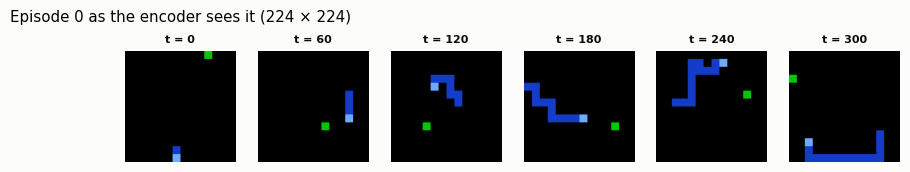

In [3]:
ep = episodes[0]
steps = np.linspace(0, len(ep["frames"]) - 1, 6).astype(int)
fig, axes = plt.subplots(1, 6, figsize=(10, 2))
for ax, t in zip(axes, steps, strict=True):
    ax.imshow(ep["frames"][t].repeat(16, 0).repeat(16, 1))
    ax.set_title(f"t = {t}", fontsize=8)
    ax.axis("off")
fig.suptitle("Episode 0 as the encoder sees it (224 × 224)", x=0.01, ha="left")
fig.savefig(FIGS / "phase1_filmstrip.png")
plt.show()

## 2. Probe results

Ridge probes on mean-pooled patch tokens (held-out R²_joint, mean of x/y):

| probe | features → target | trivial floor |
|---|---|---|
| encoder | `z_t → head_t` | — |
| predictor | `ẑ_{t+1} → head_{t+1}` | copy `head_t` scores 0.97 |
| displacement | `ẑ_{t+1} → Δhead` | state-only guess (identity WM) |
| change | `ẑ_{t+1} − z_t → Δhead` | exactly 0 for the identity WM |

In [4]:
frozen = load("dinov2_frozen", "probe.json")
runs = {"Direct WM": "dinov2_wm", "Residual WM": "dinov2_wm_residual"}
rows = {
    "Identity WM": {
        "predictor": frozen["identity_predictor"]["r2_joint"],
        "displacement": frozen["identity_displacement"]["r2_joint"],
        "change": frozen["identity_change"]["r2_joint"],
    }
}
for label, run in runs.items():
    rows[label] = {k: v["r2_joint"] for k, v in load(run, "probe.json").items()}

# Control: how much of the displacement can be read off the action alone?
eps, train_names, val_names = load_split(ROOT / "data/episodes", 0.2, 0)


def action_xy(names):
    """One-hot action -> head displacement, alive transitions only."""
    xs, ys = [], []
    for n in names:
        e, m = eps[n], eps[n]["alive"][1:]
        xs.append(np.eye(5)[e["actions"]][m])
        ys.append((e["heads"][1:] - e["heads"][:-1])[m])
    return np.concatenate(xs).astype(float), np.concatenate(ys).astype(float)


action_only = fit_probe(*action_xy(train_names), *action_xy(val_names)).r2_joint
rows["Action only (no image)"] = {"displacement": action_only}
probes = pd.DataFrame(rows).T[["predictor", "displacement", "change"]]
print(f"Frozen DINOv2 encoder probe (ceiling): {frozen['encoder']['r2_joint']:.3f}")
probes.round(3)

Frozen DINOv2 encoder probe (ceiling): 0.932


,predictor,displacement,change
Identity WM,0.907,0.391,-0.000
Direct WM,0.923,0.839,0.772
Residual WM,0.928,0.553,0.873
Action only (no image),NaN,0.881,NaN


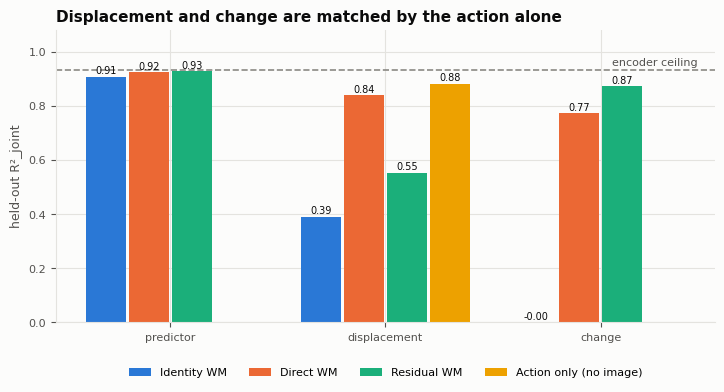

In [5]:
metrics = ["predictor", "displacement", "change"]
models = list(probes.index)
x = np.arange(len(metrics))
width = 0.2
fig, ax = plt.subplots(figsize=(8.5, 3.8))
for i, model in enumerate(models):
    vals = probes.loc[model, metrics].to_numpy(dtype=float)
    offset = (i - (len(models) - 1) / 2) * width
    bars = ax.bar(
        x + offset,
        np.nan_to_num(vals),
        width * 0.92,
        color=style.SERIES[i],
        label=model,
    )
    for b, v in zip(bars, vals, strict=True):
        if np.isnan(v):
            continue
        ax.annotate(
            f"{v:.2f}",
            (b.get_x() + b.get_width() / 2, max(v, 0)),
            textcoords="offset points",
            xytext=(0, 2),
            ha="center",
            fontsize=7,
            color=style.TEXT,
        )
ax.axhline(frozen["encoder"]["r2_joint"], color=style.BASELINE, ls="--", lw=1.2)
ax.annotate(
    "encoder ceiling",
    (x[-1] + 0.45, frozen["encoder"]["r2_joint"]),
    textcoords="offset points",
    xytext=(0, 3),
    ha="right",
    fontsize=8,
    color=style.TEXT_MUTED,
)
ax.set_xticks(x, metrics)
ax.set_ylim(0, 1.08)
ax.set_ylabel("held-out R²_joint")
ax.set_title("Displacement and change are matched by the action alone", loc="left")
ax.legend(ncols=4, loc="upper center", bbox_to_anchor=(0.5, -0.12))
fig.savefig(FIGS / "phase1_probes.png")
plt.show()

## 3. Feature-space error: the world models against copying the input

In [6]:
hist = {label: pd.DataFrame(load(run, "history.json")) for label, run in runs.items()}
last = {label: h.iloc[-1] for label, h in hist.items()}
errors = pd.DataFrame(
    {
        "Identity WM": {
            "val MSE": last["Direct WM"]["identity_mse"],
            "val cos": last["Direct WM"]["identity_cos"],
        },
        **{
            k: {"val MSE": v["val_mse"], "val cos": v["val_cos"]}
            for k, v in last.items()
        },
    }
).T
errors.round(4)

,val MSE,val cos
Identity WM,0.2234,0.9836
Direct WM,0.2433,0.9826
Residual WM,0.1342,0.9902


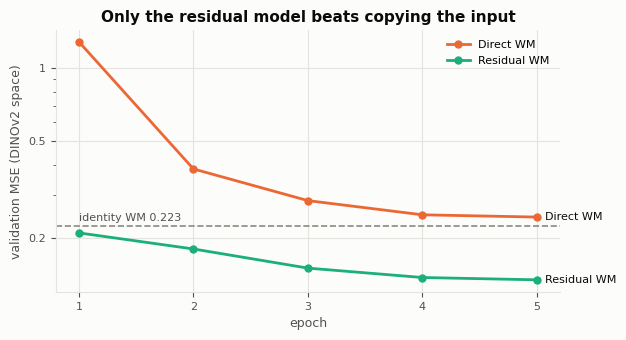

In [7]:
fig, ax = plt.subplots(figsize=(6.5, 3.4))
for i, (label, h) in enumerate(hist.items(), start=1):
    ax.plot(h["epoch"], h["val_mse"], marker="o", color=style.SERIES[i], label=label)
    ax.annotate(
        label,
        (h["epoch"].iloc[-1], h["val_mse"].iloc[-1]),
        textcoords="offset points",
        xytext=(6, 0),
        va="center",
        fontsize=8,
        color=style.TEXT,
    )
ident = hist["Direct WM"]["identity_mse"].iloc[0]
ax.axhline(ident, color=style.BASELINE, ls="--", lw=1.2)
ax.annotate(
    f"identity WM {ident:.3f}",
    (1, ident),
    textcoords="offset points",
    xytext=(0, 4),
    fontsize=8,
    color=style.TEXT_MUTED,
)
ax.set(
    xlabel="epoch",
    ylabel="validation MSE (DINOv2 space)",
    title="Only the residual model beats copying the input",
)
style.log_axis(ax)
ax.set_xticks(hist["Direct WM"]["epoch"])
ax.legend(loc="upper right")
fig.savefig(FIGS / "phase1_val_mse.png")
plt.show()

## 4. Findings

1. **The ceiling reproduces.** Frozen DINOv2's encoder probe matches the original write-up (0.927) to within about 0.005.
2. **The original predictor probe is saturated.** The identity WM, which knows nothing about dynamics, already scores about 0.91, because the head moves at most one cell per step. It can't rank world models.
3. **Only the residual WM beats copying the input on MSE.** The direct WM never does (as in the original): it must re-synthesise about 250 near-static patches and pays a small error on each.
4. **Correction: the displacement and change probes measure the action, not the dynamics.** I first read the direct WM's displacement score (0.84 vs 0.39 for identity) as evidence that it learned dynamics. The **action-only control** (a one-hot of the action, with no image) reaches about 0.88, because actions are absolute directions, so Δhead ≈ action. A predictor can score well by passing its action token through. Neither world model beats that control. A collapsed JEPA (Phase 2) scores 0.88 too.
5. **What a fair dynamics test needs:** decode the *predicted* latent with a probe fitted only on *real* encodings (probe transfer). Then passing the action through doesn't help unless the prediction lands where the true next frame's encoding would be.

Details, failures and reasoning: [`docs/devlog.md`](../docs/devlog.md).